Mounted at /content/drive
Loaded 5152 policy-question results

Main results
                      Method  Macro Precision  Macro Recall  Macro F1  Exact Match  Complete Recall  Micro F1  Actions  Retrieved Edges
              Relation fixed           0.2683        0.4461    0.3017       0.1128           0.4062    0.3866  12.0000         148.5557
Learned ranker, fixed budget           0.3047        0.4966    0.3384       0.1277           0.4592    0.4148  12.0000         171.0367
                     SetStop           0.3826        0.4359    0.3856       0.2772           0.3927    0.4722   5.9524         110.2758
               Oracle ranker           0.4643        0.5280    0.4698       0.3383           0.4755    0.5981   8.0978         166.3859

Ablation results
       Configuration Learned Ranking Learned Stopping  Macro F1  Exact Match  Actions
  Relation heuristic              No               No    0.3017       0.1128  12.0000
Learned ranking only             Yes               No 

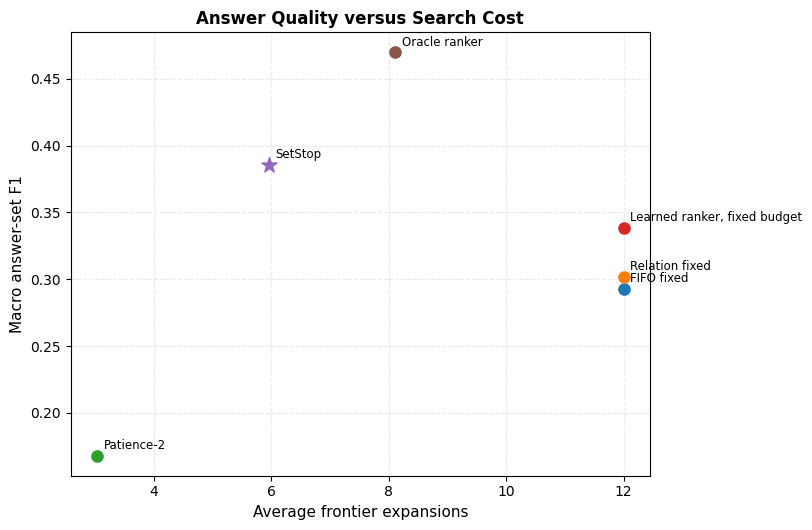

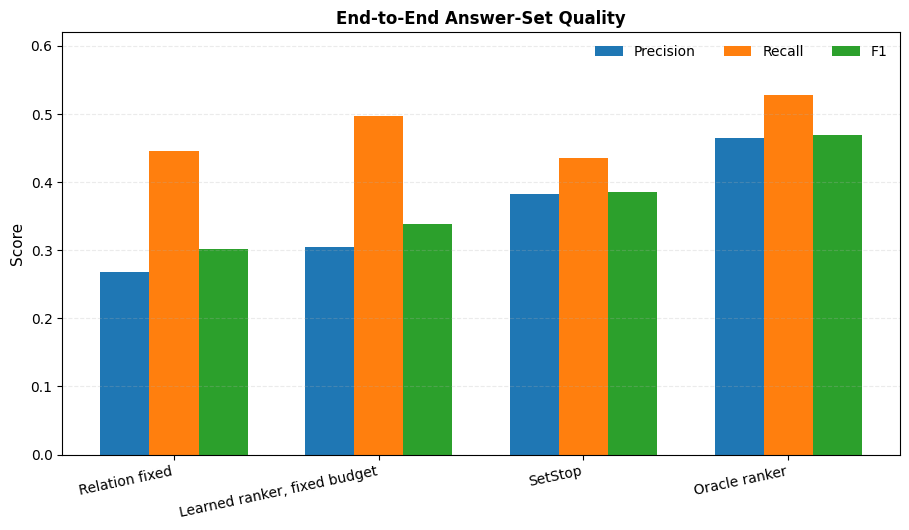


PAPER ANALYSIS COMPLETED
{
  "dataset": "WebQSP multi-answer subset",
  "test_questions": 736,
  "setstop": {
    "macro_precision": 0.3825526979679622,
    "macro_recall": 0.4359092222506889,
    "macro_f1": 0.38563954842883136,
    "micro_f1": 0.47224576271186447,
    "exact_match": 0.27717391304347827,
    "actions": 5.952445652173913,
    "retrieved_edges": 110.2758152173913,
    "premature_stop_rate": 0.33695652173913043
  },
  "versus_fixed_ranker": {
    "macro_f1_difference": 0.04726766941691668,
    "exact_match_difference": 0.14945652173913043,
    "action_reduction_percent": 50.396286231884055,
    "edge_reduction_percent": 35.52505103945728
  },
  "versus_relation_baseline": {
    "macro_f1_difference": 0.08395743263381023,
    "exact_match_difference": 0.1644021739130435,
    "action_reduction_percent": 50.396286231884055,
    "edge_reduction_percent": 25.76803826700934
  },
  "limitations": [
    "The evaluation uses one primary dataset.",
    "SetStop prematurely stops 

In [1]:
# ============================================================
# SetStop-KGQA Notebook 07
# Paper Ablations, Error Analysis and Figures
# Complete single-cell CPU code
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import collections
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/SetStop_KGQA"
)

INPUT_ROOT = (
    ROOT / "outputs/end_to_end_test_v1"
)

OUTPUT_ROOT = (
    ROOT / "outputs/paper_analysis_v1"
)

OUTPUT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

SUMMARY_PATH = (
    INPUT_ROOT
    / "end_to_end_summary_v1.json"
)

PAIRED_PATH = (
    INPUT_ROOT
    / "end_to_end_paired_comparisons_v1.json"
)

PER_QUESTION_PATH = (
    INPUT_ROOT
    / "end_to_end_per_question_v1.jsonl"
)

for path in [
    SUMMARY_PATH,
    PAIRED_PATH,
    PER_QUESTION_PATH,
]:
    assert path.exists(), f"Missing: {path}"


# ============================================================
# 2. LOAD RESULTS
# ============================================================

summary = json.loads(
    SUMMARY_PATH.read_text(
        encoding="utf-8"
    )
)

paired = json.loads(
    PAIRED_PATH.read_text(
        encoding="utf-8"
    )
)

per_question = []

with open(
    PER_QUESTION_PATH,
    encoding="utf-8"
) as file:
    for line in file:
        if line.strip():
            per_question.append(
                json.loads(line)
            )

results_df = pd.DataFrame(
    per_question
)

assert len(results_df) == 736 * 7
assert results_df["qid"].nunique() == 736

print(
    "Loaded",
    len(results_df),
    "policy-question results"
)


# ============================================================
# 3. POLICY NAMES
# ============================================================

POLICY_NAMES = {
    "fifo_fixed_e2e":
        "FIFO fixed",

    "relation_fixed_e2e":
        "Relation fixed",

    "patience2_e2e":
        "Patience-2",

    "random_fixed_e2e":
        "Random fixed",

    "model_fixed_e2e":
        "Learned ranker, fixed budget",

    "setstop_e2e":
        "SetStop",

    "oracle_rank_e2e":
        "Oracle ranker",
}

MAIN_POLICIES = [
    "relation_fixed_e2e",
    "model_fixed_e2e",
    "setstop_e2e",
    "oracle_rank_e2e",
]


# ============================================================
# 4. MAIN RESULTS TABLE
# ============================================================

main_rows = []

for policy in MAIN_POLICIES:
    result = summary[policy]

    main_rows.append({
        "Method": POLICY_NAMES[policy],

        "Macro Precision":
            result["precision"]["mean"],

        "Macro Recall":
            result["recall"]["mean"],

        "Macro F1":
            result["answer_f1"]["mean"],

        "Exact Match":
            result["exact_match"]["mean"],

        "Complete Recall":
            result["complete_recall"]["mean"],

        "Micro F1":
            result["micro_f1"],

        "Actions":
            result["actions"]["mean"],

        "Retrieved Edges":
            result["retrieved_edges"]["mean"],
    })

main_table = pd.DataFrame(
    main_rows
)

main_csv = (
    OUTPUT_ROOT
    / "main_results_table_v1.csv"
)

main_tex = (
    OUTPUT_ROOT
    / "main_results_table_v1.tex"
)

main_table.to_csv(
    main_csv,
    index=False
)

main_table.to_latex(
    main_tex,
    index=False,
    float_format="%.4f",
    caption=(
        "End-to-end results on the "
        "WebQSP multi-answer test subset."
    ),
    label="tab:main_results",
)

print("\nMain results")
print(
    main_table.to_string(
        index=False,
        float_format=lambda value:
            f"{value:.4f}"
    )
)


# ============================================================
# 5. ABLATION TABLE
# ============================================================

ablation_rows = [
    {
        "Configuration":
            "Relation heuristic",

        "Learned Ranking": "No",
        "Learned Stopping": "No",

        "Macro F1":
            summary[
                "relation_fixed_e2e"
            ]["answer_f1"]["mean"],

        "Exact Match":
            summary[
                "relation_fixed_e2e"
            ]["exact_match"]["mean"],

        "Actions":
            summary[
                "relation_fixed_e2e"
            ]["actions"]["mean"],
    },
    {
        "Configuration":
            "Learned ranking only",

        "Learned Ranking": "Yes",
        "Learned Stopping": "No",

        "Macro F1":
            summary[
                "model_fixed_e2e"
            ]["answer_f1"]["mean"],

        "Exact Match":
            summary[
                "model_fixed_e2e"
            ]["exact_match"]["mean"],

        "Actions":
            summary[
                "model_fixed_e2e"
            ]["actions"]["mean"],
    },
    {
        "Configuration":
            "SetStop",

        "Learned Ranking": "Yes",
        "Learned Stopping": "Yes",

        "Macro F1":
            summary[
                "setstop_e2e"
            ]["answer_f1"]["mean"],

        "Exact Match":
            summary[
                "setstop_e2e"
            ]["exact_match"]["mean"],

        "Actions":
            summary[
                "setstop_e2e"
            ]["actions"]["mean"],
    },
    {
        "Configuration":
            "Oracle ranking",

        "Learned Ranking": "Oracle",
        "Learned Stopping": "Oracle",

        "Macro F1":
            summary[
                "oracle_rank_e2e"
            ]["answer_f1"]["mean"],

        "Exact Match":
            summary[
                "oracle_rank_e2e"
            ]["exact_match"]["mean"],

        "Actions":
            summary[
                "oracle_rank_e2e"
            ]["actions"]["mean"],
    },
]

ablation_table = pd.DataFrame(
    ablation_rows
)

ablation_table.to_csv(
    OUTPUT_ROOT
    / "ablation_table_v1.csv",
    index=False,
)

ablation_table.to_latex(
    OUTPUT_ROOT
    / "ablation_table_v1.tex",
    index=False,
    float_format="%.4f",
    caption=(
        "Ablation of learned frontier "
        "ranking and stopping."
    ),
    label="tab:ablation",
)

print("\nAblation results")
print(
    ablation_table.to_string(
        index=False,
        float_format=lambda value:
            f"{value:.4f}"
    )
)


# ============================================================
# 6. STATISTICAL COMPARISONS
# ============================================================

comparison_rows = []

for baseline in [
    "relation_fixed_e2e",
    "model_fixed_e2e",
]:
    for metric in [
        "precision",
        "recall",
        "answer_f1",
        "exact_match",
        "actions",
        "retrieved_edges",
    ]:
        comparison = (
            paired[baseline][metric]
        )

        comparison_rows.append({
            "Comparison": (
                "SetStop vs "
                + POLICY_NAMES[baseline]
            ),
            "Metric": metric,
            "Mean Difference":
                comparison[
                    "mean_difference"
                ],
            "95% CI Lower":
                comparison[
                    "ci95_lower"
                ],
            "95% CI Upper":
                comparison[
                    "ci95_upper"
                ],
            "Significant":
                comparison[
                    "significant_at_0_05"
                ],
        })

comparison_table = pd.DataFrame(
    comparison_rows
)

comparison_table.to_csv(
    OUTPUT_ROOT
    / "paired_significance_v1.csv",
    index=False,
)


# ============================================================
# 7. SUBGROUP ANALYSIS BY ANSWER COUNT
# ============================================================

setstop_df = results_df[
    results_df["policy"]
    == "setstop_e2e"
].copy()


def answer_count_group(count):
    if count == 2:
        return "2 answers"

    if count <= 5:
        return "3–5 answers"

    return "6+ answers"


setstop_df["Answer-count group"] = (
    setstop_df[
        "gold_answer_count"
    ].apply(answer_count_group)
)

subgroup_table = (
    setstop_df.groupby(
        "Answer-count group",
        sort=False
    )
    .agg(
        Questions=("qid", "count"),
        Precision=("precision", "mean"),
        Recall=("recall", "mean"),
        F1=("answer_f1", "mean"),
        Exact=("exact_match", "mean"),
        Actions=("actions", "mean"),
        Edges=("retrieved_edges", "mean"),
    )
    .reset_index()
)

subgroup_table.to_csv(
    OUTPUT_ROOT
    / "subgroup_by_answer_count_v1.csv",
    index=False,
)

print("\nSetStop by answer count")
print(
    subgroup_table.to_string(
        index=False,
        float_format=lambda value:
            f"{value:.4f}"
    )
)


# ============================================================
# 8. ERROR CATEGORIES
# ============================================================

def error_category(row):
    false_positive = int(
        row["false_positive_count"]
    )

    false_negative = int(
        row["false_negative_count"]
    )

    predicted = int(
        row["predicted_answer_count"]
    )

    if (
        false_positive == 0
        and false_negative == 0
    ):
        return "Exact"

    if predicted == 0:
        return "Empty prediction"

    if (
        false_positive > 0
        and false_negative == 0
    ):
        return "Over-prediction only"

    if (
        false_positive == 0
        and false_negative > 0
    ):
        return "Incomplete only"

    return "Mixed FP and FN"


setstop_df["Error category"] = (
    setstop_df.apply(
        error_category,
        axis=1
    )
)

error_order = [
    "Exact",
    "Incomplete only",
    "Over-prediction only",
    "Mixed FP and FN",
    "Empty prediction",
]

error_counts = (
    setstop_df[
        "Error category"
    ]
    .value_counts()
    .reindex(
        error_order,
        fill_value=0
    )
)

error_table = pd.DataFrame({
    "Error Category":
        error_counts.index,

    "Questions":
        error_counts.values,
})

error_table["Percentage"] = (
    error_table["Questions"]
    / len(setstop_df)
    * 100
)

error_table.to_csv(
    OUTPUT_ROOT
    / "setstop_error_analysis_v1.csv",
    index=False,
)

print("\nSetStop error breakdown")
print(
    error_table.to_string(
        index=False,
        float_format=lambda value:
            f"{value:.2f}"
    )
)


# ============================================================
# 9. PAPER FIGURE 1: QUALITY–COST TRADE-OFF
# ============================================================

plot_policies = [
    "fifo_fixed_e2e",
    "relation_fixed_e2e",
    "patience2_e2e",
    "model_fixed_e2e",
    "setstop_e2e",
    "oracle_rank_e2e",
]

fig, ax = plt.subplots(
    figsize=(8.2, 5.4)
)

for policy in plot_policies:
    actions = summary[
        policy
    ]["actions"]["mean"]

    answer_f1 = summary[
        policy
    ]["answer_f1"]["mean"]

    if policy == "setstop_e2e":
        size = 130
        marker = "*"
        zorder = 5
    else:
        size = 65
        marker = "o"
        zorder = 3

    ax.scatter(
        actions,
        answer_f1,
        s=size,
        marker=marker,
        zorder=zorder,
    )

    ax.annotate(
        POLICY_NAMES[policy],
        (actions, answer_f1),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8.5,
    )

ax.set_xlabel(
    "Average frontier expansions",
    fontsize=11
)

ax.set_ylabel(
    "Macro answer-set F1",
    fontsize=11
)

ax.set_title(
    "Answer Quality versus Search Cost",
    fontsize=12,
    fontweight="bold",
)

ax.grid(
    alpha=0.25,
    linestyle="--"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_ROOT
    / "quality_cost_tradeoff_v1.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    OUTPUT_ROOT
    / "quality_cost_tradeoff_v1.pdf",
    bbox_inches="tight",
)

plt.show()


# ============================================================
# 10. PAPER FIGURE 2: MAIN QUALITY METRICS
# ============================================================

figure_policies = [
    "relation_fixed_e2e",
    "model_fixed_e2e",
    "setstop_e2e",
    "oracle_rank_e2e",
]

labels = [
    POLICY_NAMES[policy]
    for policy in figure_policies
]

precision_values = [
    summary[policy][
        "precision"
    ]["mean"]
    for policy in figure_policies
]

recall_values = [
    summary[policy][
        "recall"
    ]["mean"]
    for policy in figure_policies
]

f1_values = [
    summary[policy][
        "answer_f1"
    ]["mean"]
    for policy in figure_policies
]

positions = np.arange(
    len(labels)
)

width = 0.24

fig, ax = plt.subplots(
    figsize=(9.2, 5.4)
)

ax.bar(
    positions - width,
    precision_values,
    width,
    label="Precision",
)

ax.bar(
    positions,
    recall_values,
    width,
    label="Recall",
)

ax.bar(
    positions + width,
    f1_values,
    width,
    label="F1",
)

ax.set_xticks(positions)
ax.set_xticklabels(
    labels,
    rotation=12,
    ha="right"
)

ax.set_ylabel(
    "Score",
    fontsize=11
)

ax.set_ylim(0, 0.62)

ax.set_title(
    "End-to-End Answer-Set Quality",
    fontsize=12,
    fontweight="bold",
)

ax.legend(
    frameon=False,
    ncol=3
)

ax.grid(
    axis="y",
    alpha=0.25,
    linestyle="--"
)

fig.tight_layout()

fig.savefig(
    OUTPUT_ROOT
    / "answer_quality_comparison_v1.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    OUTPUT_ROOT
    / "answer_quality_comparison_v1.pdf",
    bbox_inches="tight",
)

plt.show()


# ============================================================
# 11. COMPACT PAPER SUMMARY
# ============================================================

setstop = summary["setstop_e2e"]
fixed = summary["model_fixed_e2e"]
relation = summary["relation_fixed_e2e"]

paper_summary = {
    "dataset": (
        "WebQSP multi-answer subset"
    ),

    "test_questions": 736,

    "setstop": {
        "macro_precision":
            setstop["precision"]["mean"],

        "macro_recall":
            setstop["recall"]["mean"],

        "macro_f1":
            setstop["answer_f1"]["mean"],

        "micro_f1":
            setstop["micro_f1"],

        "exact_match":
            setstop["exact_match"]["mean"],

        "actions":
            setstop["actions"]["mean"],

        "retrieved_edges":
            setstop[
                "retrieved_edges"
            ]["mean"],

        "premature_stop_rate":
            setstop[
                "premature_stop"
            ]["mean"],
    },

    "versus_fixed_ranker": {
        "macro_f1_difference":
            setstop["answer_f1"]["mean"]
            - fixed["answer_f1"]["mean"],

        "exact_match_difference":
            setstop["exact_match"]["mean"]
            - fixed["exact_match"]["mean"],

        "action_reduction_percent":
            (
                1
                - setstop["actions"]["mean"]
                / fixed["actions"]["mean"]
            ) * 100,

        "edge_reduction_percent":
            (
                1
                - setstop[
                    "retrieved_edges"
                ]["mean"]
                / fixed[
                    "retrieved_edges"
                ]["mean"]
            ) * 100,
    },

    "versus_relation_baseline": {
        "macro_f1_difference":
            setstop["answer_f1"]["mean"]
            - relation[
                "answer_f1"
            ]["mean"],

        "exact_match_difference":
            setstop["exact_match"]["mean"]
            - relation[
                "exact_match"
            ]["mean"],

        "action_reduction_percent":
            (
                1
                - setstop["actions"]["mean"]
                / relation["actions"]["mean"]
            ) * 100,

        "edge_reduction_percent":
            (
                1
                - setstop[
                    "retrieved_edges"
                ]["mean"]
                / relation[
                    "retrieved_edges"
                ]["mean"]
            ) * 100,
    },

    "limitations": [
        (
            "The evaluation uses one "
            "primary dataset."
        ),
        (
            "SetStop prematurely stops "
            "while a gold answer remains "
            "reachable in some cases."
        ),
        (
            "The answer recognizer has "
            "higher recall than precision."
        ),
    ],
}

summary_output_path = (
    OUTPUT_ROOT
    / "conference_paper_summary_v1.json"
)

summary_output_path.write_text(
    json.dumps(
        paper_summary,
        indent=2
    ),
    encoding="utf-8",
)

print("\n" + "=" * 90)
print("PAPER ANALYSIS COMPLETED")
print("=" * 90)
print(json.dumps(
    paper_summary,
    indent=2
))
print("\nOutputs saved to:")
print(OUTPUT_ROOT)
print("=" * 90)